In [533]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

In [534]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data}, label={self.label}, op='{self._op}')"
    
    def __add__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1. * out.grad
            other.grad += 1. * out.grad
        out._backward = _backward
        return out

    def __radd__(self,other):
        return self + other

    def __mul__(self, other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def __rmul__(self,other):
        return self * other

    def __truediv__(self, other):
        return self * other**-1

    def __pow__(self,other):
        assert isinstance(other,(int, float))
        out = Value(self.data**other, (self, ), f"**{other}")
        def _backward():
            self.grad += (other * self.data ** (other-1)) * out.grad
        out._backward = _backward
        return out
    
    def __neg__(self):
        return self * -1
    
    def __sub__(self, other):
        return self + (-other)
    
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
            # out.grad = (1 - t**2) * self.grad
        out._backward = _backward

        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.

        for node in reversed(topo):
            node._backward()


In [535]:
a = Value(10.)
b = a / 5.
b

Value(data=2.0, label=, op='*')

$$
f(x) = an^b
$$
$$
\frac{df}{dx} = abn^{b-1}
$$

In [536]:
a = Value(2., label='a')
b = Value(-3., label='b')
c = Value(10., label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2., label='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0, label=L, op='*')

In [537]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(
        format="svg",
        graph_attr={'rankdir':'LR'}
    )
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # print(uid)
        dot.node(
            name=uid,
            label=f"{n.label} | data: {n.data:.4f} | grad: {n.grad:.4f}",
            shape='record',
        )
        if n._op:
            dot.node(
                name=uid + n._op,
                label=n._op
            )
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)


    return dot

In [538]:
L.grad = 1.0
f.grad = 4
d.grad = -2

In [539]:
e.grad = d.grad
c.grad = d.grad

b.grad = e.grad * 2.
a.grad = e.grad * -3.

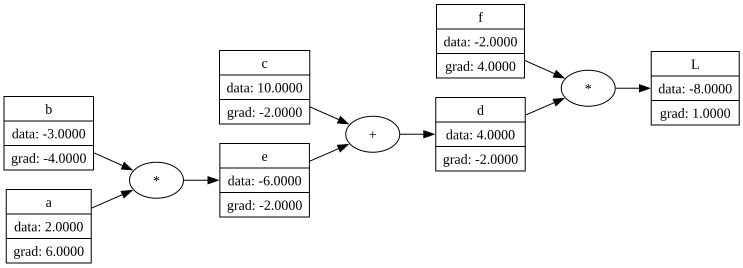

In [540]:
draw_dot(L)

#### Figure 1

<div style="text-align:right">

*1.1*
$$
\frac{dL}{dc} = \frac{dL}{dd} * \frac{dd}{dc}
$$

*1.2*
$$
d = c + e
$$

*1.3*
$$
\frac{\delta d}{\delta c} = 1
$$

*1.4*
$$
L = df
$$

*1.5*
$$
\frac{dL}{dd} = f
$$

*1.6*
$$
\frac{dL}{dc} = f * 1
$$

</div>

#### Figure 2

<div style="text-align:right">

*2.1*
$$
\frac{dL}{da} = \frac{dL}{dd} * \frac{dd}{de} * \frac{de}{da}
$$

*2.2*
$$
\frac{\delta d}{\delta e} = 1
$$

*2.3*
$$
e = ab
$$

*2.4*
$$
\frac{\delta e}{\delta a} = b
$$

*2.5*
$$
\frac{dL}{da} = f * 1 * b
$$


In [541]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f

print(L.data)

-7.286496


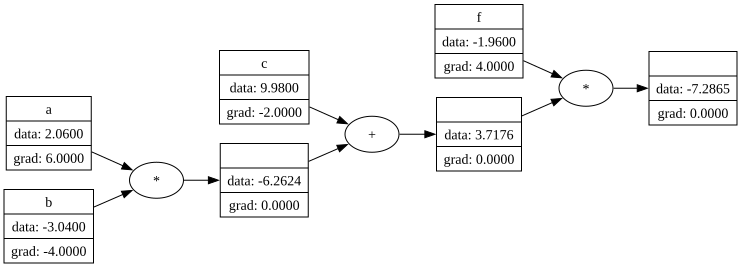

In [542]:
draw_dot(L)

In [543]:
def b():
    h = 0.0001

    a = Value(2., label='a')
    b = Value(-3., label='b')
    c = Value(10., label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2., label='f')
    L = d * f; L.label = 'L'
    L1 = L.data

    a = Value(2., label='a')
    b = Value(-3., label='b')
    b.data += h
    c = Value(10., label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2. + h, label='f')
    L = d * f; L.label = 'L'
    L2 = L.data

    print((L2 - L1)/h)

b()

0.0001999999899027216


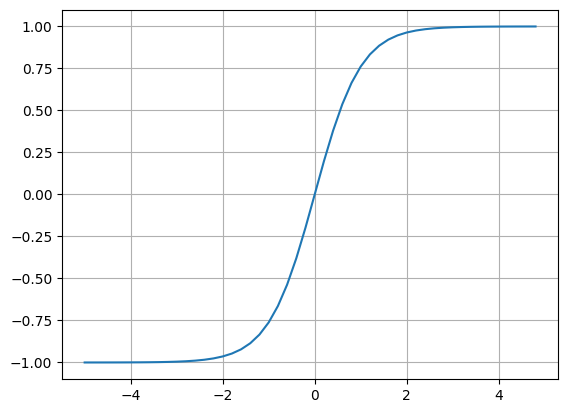

In [544]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)), label='tanh')
plt.grid()

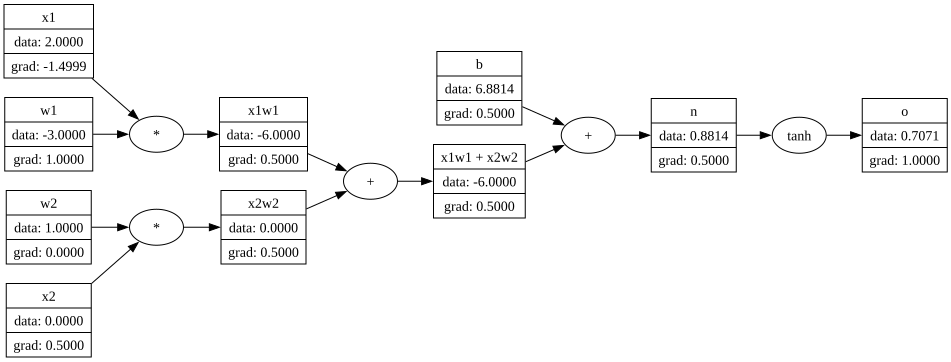

In [545]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3., label='w1')
w2 = Value(1., label='w2')

b = Value(6.8814, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'
o.backward()

draw_dot(o)



In [546]:
o.grad = 1.

In [547]:
# o._backward()
prop = [
    o,
    n,
    x1w1x2w2,
    b,
    x1w1,
    x2w2,
    x1,
    w1,
    x2,
    w2,
]

# for n in prop:
#     n._backward()

In [548]:
# topo = []
# visited = set()
# def build_topo(v):
#     if v not in visited:
#         visited.add(v)
#         for child in v._prev:
#             build_topo(child)
#         topo.append(v)
# build_topo(o)
# topo

In [549]:

# for node in reversed(topo):
#     node._backward()
#     if node.label == "+":
#         print(f"node({node.label}): {node.grad}")

In [550]:
# o.grad = 1.0
# n.grad = (1 - o.data**2) # dt/dx = 1 - t(x) 
# x1w1x2w2.grad = n.grad
# b.grad = n.grad
# x2w2.grad = x1w1x2w2.grad
# x1w1.grad = x1w1x2w2.grad

# # base
# x1.grad = w1.data * x1w1.grad
# w1.grad = x1.data * x1w1.grad
# x2.grad = w2.data * x2w2.grad
# w2.grad = x2.data * x2w2.grad


In [551]:
o.backward()

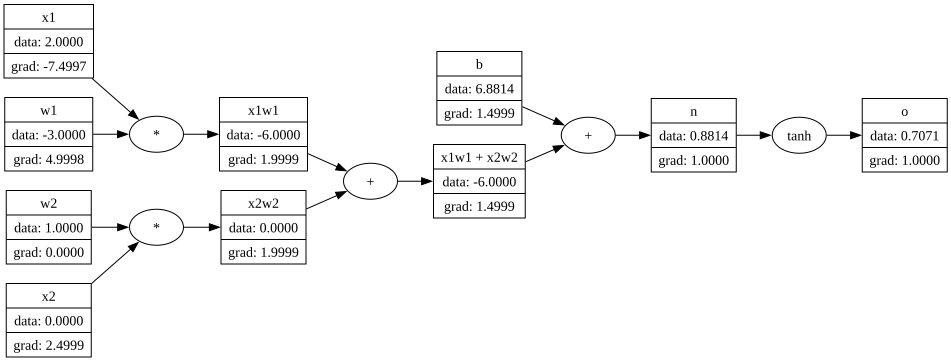

In [552]:
draw_dot(o)

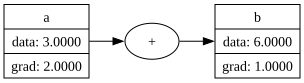

In [553]:
a = Value(3., label='a')
b = a + a; b.label = 'b'
b.backward()
draw_dot(b)

In [554]:
2. + a

Value(data=5.0, label=, op='+')

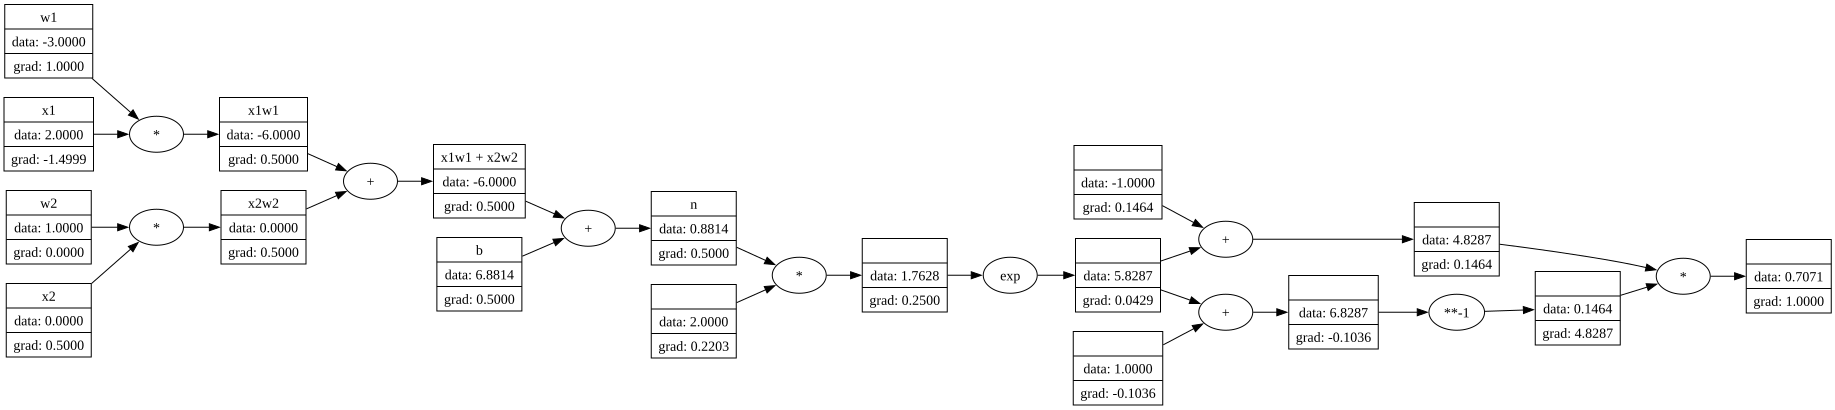

In [555]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3., label='w1')
w2 = Value(1., label='w2')

b = Value(6.8814, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'

# ===========

e = (2*n).exp()
o = (e - 1) / (e + 1)

# ===========
o.backward()


draw_dot(o)

In [754]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(np.random.uniform(-1,1)) for _ in range(nin)]
        self.b = (Value(np.random.uniform(-1,1)))

    def __repr__(self):
        msg = f"[ "
        for w in self.w:
            msg += f"{w}, "
        msg = msg[:-2] + "]"
        return msg

    def __call__(self, x):
        act = sum([wi*xi for wi, xi in zip(self.w, x)], self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] 
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        # params = []
        # for n in self.neurons:
            # ps = n.parameters()
            # params.extend(ps)
        # return params

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [755]:
x = [2.,3., -1.]
n = MLP(3,[4,4,1])
a = n(x)

In [757]:
a

Value(data=-0.2544962009705952, label=, op='tanh')

In [756]:
n.parameters()

[Value(data=0.5591193966526835, label=, op=''),
 Value(data=-0.43092021656927715, label=, op=''),
 Value(data=-0.016609029560962885, label=, op=''),
 Value(data=-0.1663933614707358, label=, op=''),
 Value(data=-0.2532540404605308, label=, op=''),
 Value(data=0.9886924393086358, label=, op=''),
 Value(data=0.9103806992588834, label=, op=''),
 Value(data=0.8091049207369376, label=, op=''),
 Value(data=0.8615789005700716, label=, op=''),
 Value(data=0.3647016198603823, label=, op=''),
 Value(data=-0.22094860746645972, label=, op=''),
 Value(data=-0.14301530199297519, label=, op=''),
 Value(data=0.18059715218841, label=, op=''),
 Value(data=0.2995010627439578, label=, op=''),
 Value(data=-0.5220401425000596, label=, op=''),
 Value(data=0.764147236439529, label=, op=''),
 Value(data=-0.20929829202958494, label=, op=''),
 Value(data=-0.047349150261187134, label=, op=''),
 Value(data=0.7353836441094317, label=, op=''),
 Value(data=-0.34682951220782865, label=, op=''),
 Value(data=-0.129938683

In [752]:
xs = [
    [2., 3., -1.],
    [3., -1., .5],
    [.5, 1., 1.],
    [1., 1., -1.]
]

ys = [1., -1., -1., 1.]


In [ ]:
llr = -0.05
steps = 20
for k in range(steps):
    # forward pass
    ypred = [n(x) for x in xs]
    loss= sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters(): # Zero Grad
        p.grad = 0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += llr * p.grad
    
    print(k, loss.data)

0 0.0009082416960928036
1 0.0009066447303028256
2 0.0009050531604114533
3 0.0009034669595727126
4 0.0009018861011167029
5 0.0009003105585481043
6 0.0008987403055448446
7 0.0008971753159566688
8 0.000895615563803709
9 0.0008940610232751739
10 0.0008925116687279189
11 0.0008909674746851267
12 0.0008894284158349767
13 0.0008878944670293379
14 0.000886365603282388
15 0.0008848417997693819
16 0.0008833230318253307
17 0.0008818092749437331
18 0.0008803005047753141
19 0.0008787966971268025


In [629]:
ypred = [n(x) for x in xs]
loss= sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=4.611870292339022, label=, op='+')

In [689]:
ypred = [n(x) for x in xs]
loss= sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=0.005003677758896597, label=, op='+')

In [690]:
loss.backward()

In [753]:
n.layers[0].neurons[0]

TypeError: __repr__ returned non-string (type NoneType)

In [692]:
for p in n.parameters():
    p.data += -0.01 * p.grad



In [740]:
ypred

[Value(data=0.9871203964242862, label=, op='tanh'),
 Value(data=-0.9952994921854477, label=, op='tanh'),
 Value(data=-0.9802074876168755, label=, op='tanh'),
 Value(data=0.9827062384453683, label=, op='tanh')]

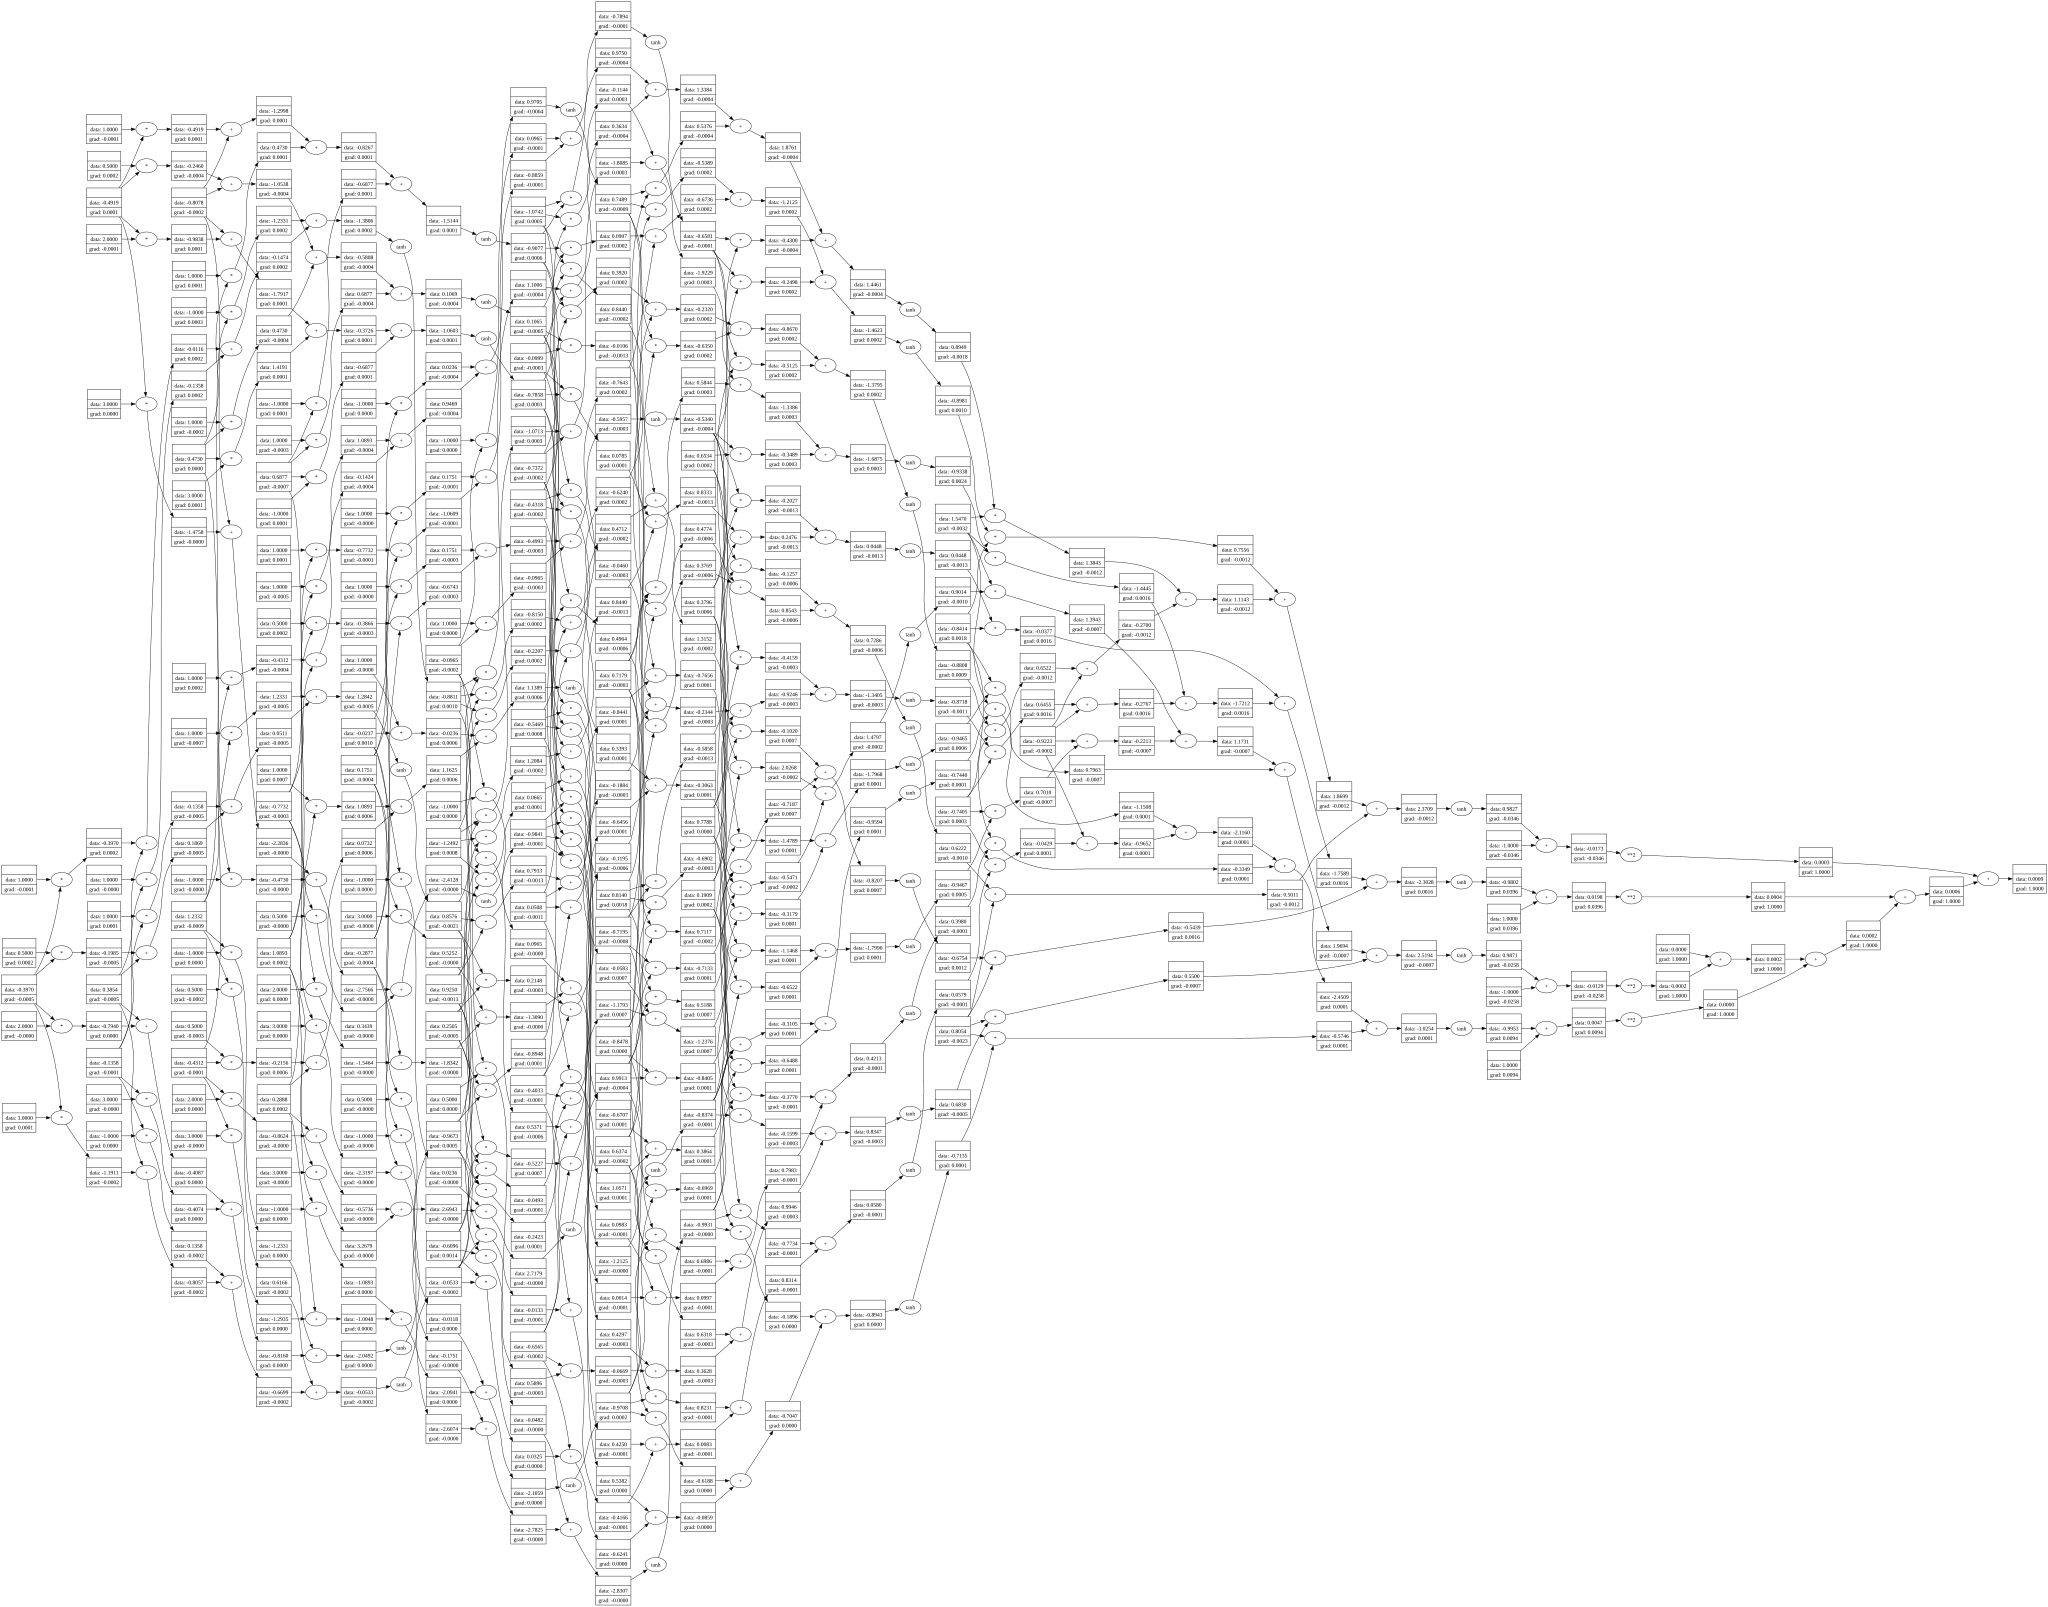

In [741]:
draw_dot(loss)